In [ ]:
import torch
print(torch.cuda.device_count())
print(torch.cuda.is_available())

## Test bi-variate Gaussian

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.signal import convolve2d

def mesh_grid(kernel_size: int) -> np.ndarray:
  ax = np.arange(-kernel_size // 2 + 1., kernel_size // 2 + 1.)
  return np.stack(np.meshgrid(ax, ax), axis=-1)

def sigma_matrix2(sig_x: float, sig_y: float, theta: float) -> np.ndarray:
  d_matrix = np.array([[sig_x**2, 0], [0, sig_y**2]])
  u_matrix = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
  return u_matrix @ d_matrix @ u_matrix.T

def pdf2(sigma_matrix: np.ndarray, grid: np.ndarray) -> np.ndarray:
  inverse_sigma = np.linalg.inv(sigma_matrix)
  kernel = np.exp(-0.5 * np.sum(np.dot(grid, inverse_sigma) * grid, 2))
  return kernel

def bivariate_Gaussian(kernel_size: int, sig_x: float, sig_y: float, theta: float, isotropic: bool) -> np.ndarray:
  grid = mesh_grid(kernel_size)
  if isotropic:
    sigma_matrix = np.array([[sig_x**2, 0], [0, sig_x**2]])
  else:
    sigma_matrix = sigma_matrix2(sig_x, sig_y, theta)
  kernel = pdf2(sigma_matrix, grid)
  kernel = kernel / np.sum(kernel)
  return kernel

def bivariate_generalized_Gaussian(kernel_size: int, sig_x: float, sig_y: float, theta: float, beta: float, isotropic: bool):
  grid = mesh_grid(kernel_size)
  if isotropic:
    sigma_matrix = np.array([[sig_x**2, 0], [0, sig_x**2]])
  else:
    sigma_matrix = sigma_matrix2(sig_x, sig_y, theta)
  inverse_sigma = np.linalg.inv(sigma_matrix)
  kernel = np.exp(-0.5 * np.power(np.sum(np.dot(grid, inverse_sigma) * grid, 2), beta))
  kernel = kernel / np.sum(kernel)
  return kernel

def plot_kernel_and_filtered_image(kernel: np.ndarray, imgpath):
  img = Image.open(imgpath).convert('RGB')
  img_np = np.array(img) / 255.0

  filtered = np.zeros_like(img_np)
  for c in range(3):
    filtered[..., c] = convolve2d(img_np[..., c], kernel, mode='same')
  
  # Create side-by-side subplots
  fig, axs = plt.subplots(1, 2, figsize=(20, 10))

  # Plot kernel
  im = axs[0].imshow(kernel, interpolation='nearest')
  fig.colorbar(im, ax=axs[0], label='Kernel weight')
  axs[0].set_title('Kernel')
  axs[0].axis('off')

  # Plot filtered image
  axs[1].imshow(np.clip(filtered, 0, 1))
  axs[1].set_title('Filtered Image')
  axs[1].axis('off')

  plt.tight_layout()
  plt.show()

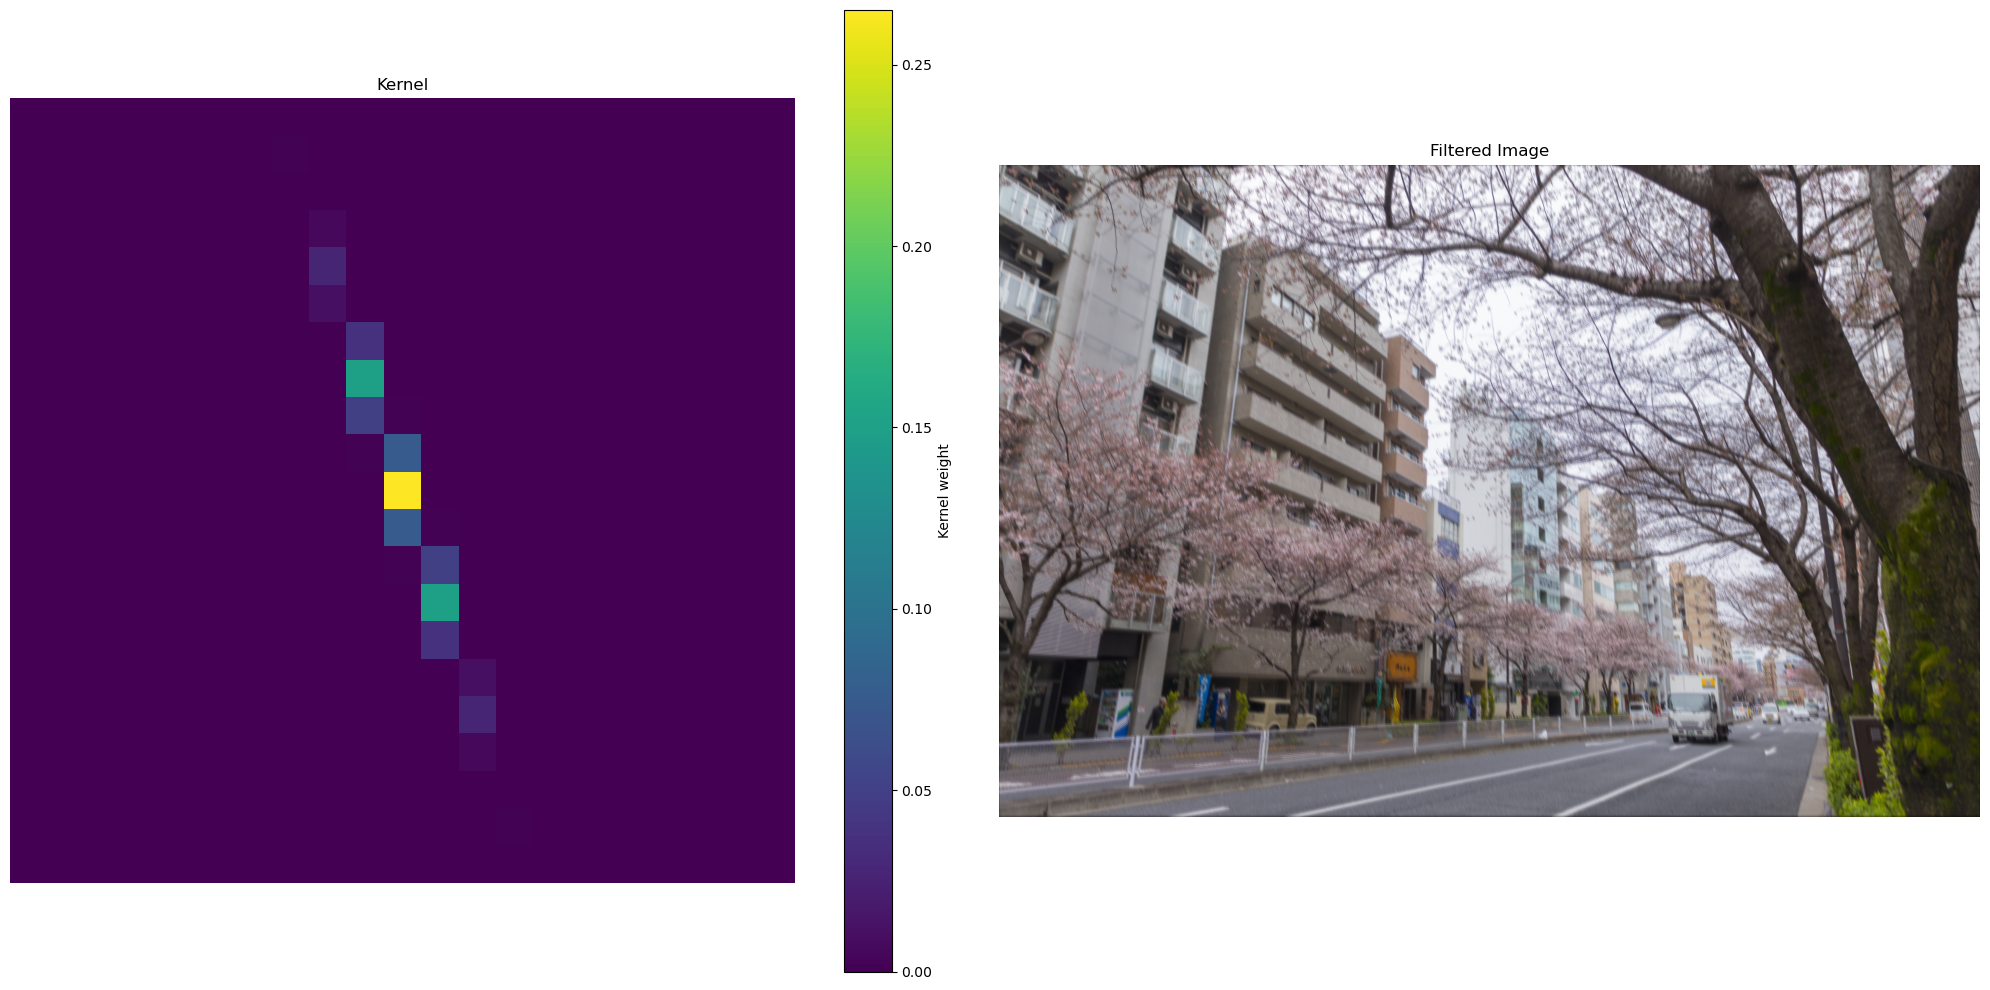

In [51]:
imgpath = '/storage/dataset/Flickr2K/000112.png'
kernel = bivariate_Gaussian(21, 3.0, 0.2, 1.2 * np.pi / 3.0, False)
plot_kernel_and_filtered_image(kernel, imgpath)